In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### データのインポート

In [2]:
df = pd.read_csv(r"/content/bank-full.csv", sep=";")

In [3]:
df = df.rename(columns={"y": "target"})
df.head(3)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no


In [4]:
df.shape

(45211, 17)

### データの前処理

In [5]:
# 重複行の確認
df.duplicated(keep=False).value_counts()

,count
False,45211


In [6]:
# 欠損値の数を確認
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [7]:
# 除外項目の検討

In [8]:
# どの特徴量をモデルに入れるか
# duration: 今回の電話で何秒話したか → この入力データはベンチマーク（性能評価）目的でのみ使用すべきであり、現実的な予測モデルの構築を目指す場合には除外する必要があります。

# 列の削除
df = df.drop(labels='duration', axis=1)

### ロジスティック回帰分析の実装

In [9]:
import os
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# 1. 使用する特徴量を指定
feature_cols = [
    "age",
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "poutcome"
]

# 入力変数と目的変数
X = df[feature_cols].copy()
y = df["target"]

# 2. 学習データとテストデータに分割
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1,
    stratify=y
)

# 3. 前処理の設定
numeric_cols = ["age"]

categorical_cols = [
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "poutcome"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

# 4. 前処理とモデルをPipelineにまとめる
model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(max_iter=1000, random_state=1)
    )
])

# 5. 学習
model.fit(x_train, y_train)

# 6. モデルの評価
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

print("【分類モデルの評価】")
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("\n【Classification Report】")
print(classification_report(y_test, y_pred_test))

# yesクラスの予測確率を取得
classifier = model.named_steps["classifier"]
yes_index = list(classifier.classes_).index("yes")

y_pred_proba = model.predict_proba(x_test)[:, yes_index]

print("Test ROC-AUC:", roc_auc_score(
    (y_test == "yes").astype(int),
    y_pred_proba
))



【分類モデルの評価】
Train Accuracy: 0.8928176446424622
Test Accuracy: 0.8919935122382778

【Classification Report】
              precision    recall  f1-score   support

          no       0.90      0.99      0.94     11977
         yes       0.66      0.16      0.25      1587

    accuracy                           0.89     13564
   macro avg       0.78      0.57      0.60     13564
weighted avg       0.87      0.89      0.86     13564

Test ROC-AUC: 0.7092507015257505


In [10]:
# モデルの保存

In [11]:
from pathlib import Path

# 保存先となるフォルダーを用意します。
# Google Colabでは、この場所はランタイムの一時的な保存領域になります。
OUTPUT_ROOT = Path("model_exports")
OUTPUT_ROOT.mkdir(exist_ok=True)

print("保存先:", OUTPUT_ROOT.resolve())

保存先: /content/model_exports


In [12]:
# 学習済みモデルを保存する
import joblib

# モデルを保存するフォルダーを作ります。
CLF_DIR = OUTPUT_ROOT / "classifier"
CLF_DIR.mkdir(exist_ok=True)

# 学習済みモデル全体をファイルに書き出します。
CLF_MODEL_PATH = CLF_DIR / "logisticRegression.pkl"
joblib.dump(model, CLF_MODEL_PATH) # joblib.dump(モデル名, 保存場所)

print("保存しました:", CLF_MODEL_PATH.resolve())

保存しました: /content/model_exports/classifier/logisticRegression.pkl


### ROC曲線のプロット

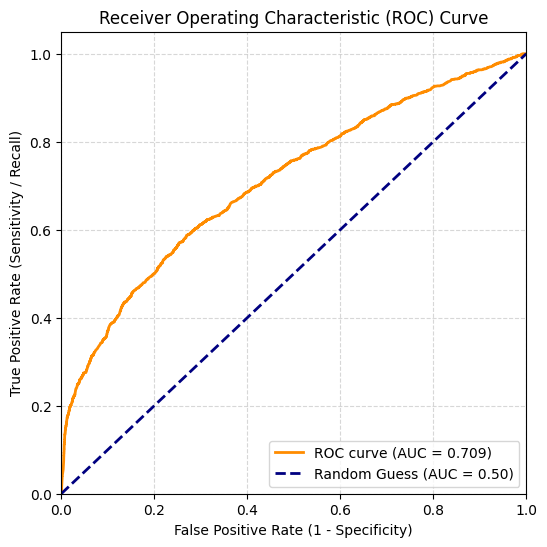

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 文字列の 'yes'/'no' を 1/0 に変換
y_test_binary = (y_test == 'yes').astype(int)

# 偽陽性率、真陽性率、閾値を計算
fpr, tpr, thresholds = roc_curve(y_test_binary, y_pred_proba)

# グラフ描画
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test_binary, y_pred_proba):.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 特徴量の影響度（オッズ比）の可視化

In [14]:
import numpy as np
import pandas as pd

# 1. Pipelineから前処理オブジェクトと分類モデルを取り出す
preprocessor_obj = model.named_steps["preprocessor"]
classifier_obj = model.named_steps["classifier"]

# 2. OneHotEncoderにより変換されたカテゴリ変数のカラム名を取得する
# 'cat'ステップ（OneHotEncoder）から自動生成された特徴量名を取得します
cat_encoder = preprocessor_obj.named_transformers_["cat"]
cat_features = list(cat_encoder.get_feature_names_out(categorical_cols))

# 前処理後のすべての特徴量名を結合
feature_names = numeric_cols + cat_features

# 3. 係数（Coefficients）の取得
coefficients = classifier_obj.coef_[0]

# オッズ比（exp(coef)）の算出
odds_ratios = np.exp(coefficients)

# 可視化用のDataFrame作成
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios
}).sort_values(by='Coefficient', ascending=False)

# 契約確率を高める要因トップ5
print("--- 契約確率を高める要因（Top 5） ---")
display(importance_df.head(5))

# 契約確率を下げる要因トップ5
print("\n--- 契約確率を下げる要因（Worst 5） ---")
display(importance_df.tail(5))

--- 契約確率を高める要因（Top 5） ---


,Feature,Coefficient,Odds Ratio
26,poutcome_success,1.601183,4.958895
6,job_retired,0.638783,1.894173
9,job_student,0.523653,1.688184
11,job_unemployed,0.167071,1.181838
20,housing_no,0.087027,1.090926



--- 契約確率を下げる要因（Worst 5） ---


,Feature,Coefficient,Odds Ratio
4,job_housemaid,-0.433214,0.648421
23,loan_yes,-0.501881,0.605391
21,housing_yes,-0.598941,0.549393
24,poutcome_failure,-0.650889,0.521582
27,poutcome_unknown,-1.098230,0.333461
